# 03 · Baseline BERT

Fine-tunes `bert-base-uncased` on the title and description as one sequence (512 tokens), compares it with the three-section model, and runs a cross-model linguistic error analysis (regex, TF-IDF and BERT).

In [ ]:
# ============================================================================
# BASELINE BERT TRAINING (for comparison with Section-Aware BERT)
# ============================================================================
#
# Run in a new cell of the original notebook
# The model is saved; training takes about 1.5 hours
#
# ============================================================================

import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import BertModel, BertTokenizer, get_linear_schedule_with_warmup
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from tqdm import tqdm

# Mount Drive
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = '/content/drive/MyDrive/nlp_project/'
os.makedirs(SAVE_DIR, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# ============================================================================
# Config
# ============================================================================
class Config:
    bert_model = 'bert-base-uncased'
    max_length = 512  # Baseline uses a longer length
    num_classes = 4
    hidden_size = 768
    dropout = 0.1
    batch_size = 16
    epochs = 3
    learning_rate = 2e-5
    warmup_ratio = 0.1

    label2id = {'Entry': 0, 'Mid': 1, 'Senior': 2, 'Executive': 3}
    id2label = {0: 'Entry', 1: 'Mid', 2: 'Senior', 3: 'Executive'}

config = Config()

# ============================================================================
# Dataset - Baseline (uses full_text)
# ============================================================================
class BaselineDataset(Dataset):
    def __init__(self, df, tokenizer, config):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.config = config

        # Create the full_text column
        if 'full_text' not in self.df.columns:
            self.df['full_text'] = (
                self.df['title'].fillna('') + ' [SEP] ' +
                self.df['description'].fillna('')
            )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        text = str(row['full_text'])

        encoding = self.tokenizer(
            text,
            max_length=self.config.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        label = self.config.label2id[row['experience_level']]

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'label': torch.tensor(label, dtype=torch.long)
        }

# ============================================================================
# Baseline BERT Model
# ============================================================================
class BaselineBERT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.bert = BertModel.from_pretrained(config.bert_model)
        self.dropout = nn.Dropout(config.dropout)
        self.classifier = nn.Linear(config.hidden_size, config.num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled = self.dropout(outputs.pooler_output)
        return self.classifier(pooled)

# ============================================================================
# Training Functions
# ============================================================================
def train_epoch(model, dataloader, optimizer, scheduler, device):
    model.train()
    total_loss = 0
    predictions, true_labels = [], []

    for batch in tqdm(dataloader, desc='Training'):
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)

        logits = model(input_ids, attention_mask)
        loss = F.cross_entropy(logits, labels)

        total_loss += loss.item()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        predictions.extend(torch.argmax(logits, dim=1).cpu().numpy())
        true_labels.extend(labels.cpu().numpy())

    return total_loss / len(dataloader), accuracy_score(true_labels, predictions)

def evaluate(model, dataloader, device):
    model.eval()
    predictions, true_labels = [], []

    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating'):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)

            logits = model(input_ids, attention_mask)
            predictions.extend(torch.argmax(logits, dim=1).cpu().numpy())
            true_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average='weighted')
    return acc, f1, predictions, true_labels

# ============================================================================
# Main Training
# ============================================================================
print("=" * 80)
print("BASELINE BERT (Full Text) Training")
print("=" * 80)

# Load data
print("\n[1] Loading data...")
train_df = pd.read_csv('train_data_final.csv', keep_default_na=False, na_values=[])
dev_df = pd.read_csv('dev_data_final.csv', keep_default_na=False, na_values=[])
test_df = pd.read_csv('test_data_final.csv', keep_default_na=False, na_values=[])

print(f"Train: {len(train_df)}, Dev: {len(dev_df)}, Test: {len(test_df)}")

# Tokenizer
print("\n[2] Initializing tokenizer...")
tokenizer = BertTokenizer.from_pretrained(config.bert_model)

# DataLoaders
print("\n[3] Creating DataLoader...")
train_loader = DataLoader(BaselineDataset(train_df, tokenizer, config),
                          batch_size=config.batch_size, shuffle=True)
dev_loader = DataLoader(BaselineDataset(dev_df, tokenizer, config),
                        batch_size=config.batch_size)
test_loader = DataLoader(BaselineDataset(test_df, tokenizer, config),
                         batch_size=config.batch_size)

# Model
print("\n[4] Initializing model...")
model = BaselineBERT(config).to(device)

optimizer = AdamW(model.parameters(), lr=config.learning_rate)
total_steps = len(train_loader) * config.epochs
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * config.warmup_ratio),
    num_training_steps=total_steps
)

# Training Loop
print("\n" + "=" * 80)
print("Training Baseline BERT")
print("=" * 80)

best_f1 = 0
for epoch in range(config.epochs):
    print(f"\n--- Epoch {epoch + 1}/{config.epochs} ---")

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, scheduler, device)
    dev_acc, dev_f1, _, _ = evaluate(model, dev_loader, device)

    print(f"Train - Loss: {train_loss:.4f}, Acc: {train_acc:.4f}")
    print(f"Dev   - Acc: {dev_acc:.4f}, F1: {dev_f1:.4f}")

    if dev_f1 > best_f1:
        best_f1 = dev_f1
        torch.save(model.state_dict(), f'{SAVE_DIR}/baseline_bert_best.pt')
        print(f"  ✓ Saved best model (F1: {dev_f1:.4f})")

# Test Evaluation
print("\n" + "=" * 80)
print("Test set evaluation")
print("=" * 80)

model.load_state_dict(torch.load(f'{SAVE_DIR}/baseline_bert_best.pt'))
test_acc, test_f1, test_preds, test_labels = evaluate(model, test_loader, device)

print(f"\nBaseline BERT Test Results:")
print(f"  Accuracy: {test_acc:.4f}")
print(f"  F1 Score: {test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(test_labels, test_preds, target_names=['Entry', 'Mid', 'Senior', 'Executive']))

# ============================================================================
# Save predictions
# ============================================================================
print("\n" + "=" * 80)
print("Saving predictions")
print("=" * 80)

test_df = test_df.reset_index(drop=True)
test_df['pred_baseline_bert'] = [config.id2label[p] for p in test_preds]

# Create the text column
if 'text' not in test_df.columns:
    test_df['text'] = test_df['title'].fillna('') + ' ' + test_df['description'].fillna('')

# Save
test_df.to_csv(f'{SAVE_DIR}/baseline_bert_predictions.csv', index=False)
np.save(f'{SAVE_DIR}/baseline_bert_test_preds.npy', test_preds)

print(f"✓ baseline_bert_predictions.csv saved")

# ============================================================================
# Compare with Section-Aware BERT
# ============================================================================
print("\n" + "=" * 80)
print("Baseline vs Section-Aware BERT")
print("=" * 80)

# Try to load the Section-Aware predictions
try:
    section_aware_df = pd.read_csv(f'{SAVE_DIR}/bert_predictions.csv')
    test_df['pred_section_bert'] = section_aware_df['pred_bert']

    # Compute each model's accuracy
    baseline_acc = (test_df['experience_level'] == test_df['pred_baseline_bert']).mean() * 100
    section_acc = (test_df['experience_level'] == test_df['pred_section_bert']).mean() * 100

    print(f"\n{'Model':<25} {'Accuracy':>12}")
    print("-" * 40)
    print(f"{'Baseline BERT':<25} {baseline_acc:>11.2f}%")
    print(f"{'Section-Aware BERT':<25} {section_acc:>11.2f}%")
    print(f"{'Difference':<25} {baseline_acc - section_acc:>+11.2f}%")

    # Per-class comparison
    print(f"\n{'Class':<12} {'Baseline':>12} {'Section-Aware':>15} {'Diff':>10}")
    print("-" * 50)

    for label in ['Entry', 'Mid', 'Senior', 'Executive']:
        mask = test_df['experience_level'] == label
        baseline_recall = (test_df.loc[mask, 'pred_baseline_bert'] == label).mean() * 100
        section_recall = (test_df.loc[mask, 'pred_section_bert'] == label).mean() * 100
        diff = baseline_recall - section_recall
        print(f"{label:<12} {baseline_recall:>11.1f}% {section_recall:>14.1f}% {diff:>+9.1f}%")

    # Analyze samples where the models disagree
    print("\n" + "-" * 50)
    print("Disagreement analysis:")

    # Baseline right, Section-Aware wrong
    baseline_wins = (
        (test_df['experience_level'] == test_df['pred_baseline_bert']) &
        (test_df['experience_level'] != test_df['pred_section_bert'])
    )

    # Section-Aware right, Baseline wrong
    section_wins = (
        (test_df['experience_level'] != test_df['pred_baseline_bert']) &
        (test_df['experience_level'] == test_df['pred_section_bert'])
    )

    # Both right
    both_correct = (
        (test_df['experience_level'] == test_df['pred_baseline_bert']) &
        (test_df['experience_level'] == test_df['pred_section_bert'])
    )

    # Both wrong
    both_wrong = (
        (test_df['experience_level'] != test_df['pred_baseline_bert']) &
        (test_df['experience_level'] != test_df['pred_section_bert'])
    )

    print(f"  Both correct: {both_correct.sum()} ({both_correct.mean()*100:.1f}%)")
    print(f"  Both wrong: {both_wrong.sum()} ({both_wrong.mean()*100:.1f}%)")
    print(f"  Baseline wins: {baseline_wins.sum()} ({baseline_wins.mean()*100:.1f}%)")
    print(f"  Section-Aware wins: {section_wins.sum()} ({section_wins.mean()*100:.1f}%)")

    # Save the comparison
    test_df['baseline_correct'] = test_df['experience_level'] == test_df['pred_baseline_bert']
    test_df['section_correct'] = test_df['experience_level'] == test_df['pred_section_bert']
    test_df.to_csv(f'{SAVE_DIR}/bert_comparison.csv', index=False)
    print(f"\n✓ bert_comparison.csv saved (predictions of both models)")

except FileNotFoundError:
    print("Section-Aware BERT predictions not found, skipping comparison")

print("\n" + "=" * 80)
print("Training complete!")
print("=" * 80)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cuda
GPU: NVIDIA A100-SXM4-80GB
BASELINE BERT (Full Text) Training

[1] 加载数据...
Train: 56501, Dev: 12108, Test: 12108

[2] 初始化 Tokenizer...

[3] 创建 DataLoader...

[4] 初始化模型...

开始训练 Baseline BERT

--- Epoch 1/3 ---


Evaluating: 100%|██████████| 757/757 [03:32<00:00,  3.57it/s]


Train - Loss: 0.7805, Acc: 0.6938
Dev   - Acc: 0.7481, F1: 0.7340
  ✓ 保存最佳模型 (F1: 0.7340)

--- Epoch 2/3 ---


Evaluating: 100%|██████████| 757/757 [03:33<00:00,  3.55it/s]


Train - Loss: 0.5763, Acc: 0.7833
Dev   - Acc: 0.7659, F1: 0.7647
  ✓ 保存最佳模型 (F1: 0.7647)

--- Epoch 3/3 ---


Evaluating: 100%|██████████| 757/757 [03:33<00:00,  3.55it/s]


Train - Loss: 0.4504, Acc: 0.8344
Dev   - Acc: 0.7779, F1: 0.7749
  ✓ 保存最佳模型 (F1: 0.7749)

测试集评估


Evaluating: 100%|██████████| 757/757 [03:31<00:00,  3.58it/s]



Baseline BERT Test Results:
  Accuracy: 0.7851
  F1 Score: 0.7818

Classification Report:
              precision    recall  f1-score   support

       Entry       0.83      0.83      0.83      4718
         Mid       0.59      0.47      0.52      1308
      Senior       0.79      0.83      0.81      5416
   Executive       0.77      0.70      0.73       666

    accuracy                           0.79     12108
   macro avg       0.74      0.71      0.72     12108
weighted avg       0.78      0.79      0.78     12108


保存预测结果
✓ baseline_bert_predictions.csv 已保存

Baseline vs Section-Aware BERT 对比

Model                         Accuracy
----------------------------------------
Baseline BERT                   78.51%
Section-Aware BERT              78.03%
Difference                      +0.48%

Class            Baseline   Section-Aware       Diff
--------------------------------------------------
Entry               83.3%           84.2%      -0.9%
Mid                 47.2%           44.

BASELINE vs SECTION-AWARE BERT 对比分析

----------------------------------------------------------------------
1. OVERALL PERFORMANCE COMPARISON
----------------------------------------------------------------------

Model                         Accuracy     Weighted F1
-------------------------------------------------------
Baseline BERT                   78.51%         0.7818
Section-Aware BERT              78.03%         0.7759
Difference                      -0.48%        -0.0059


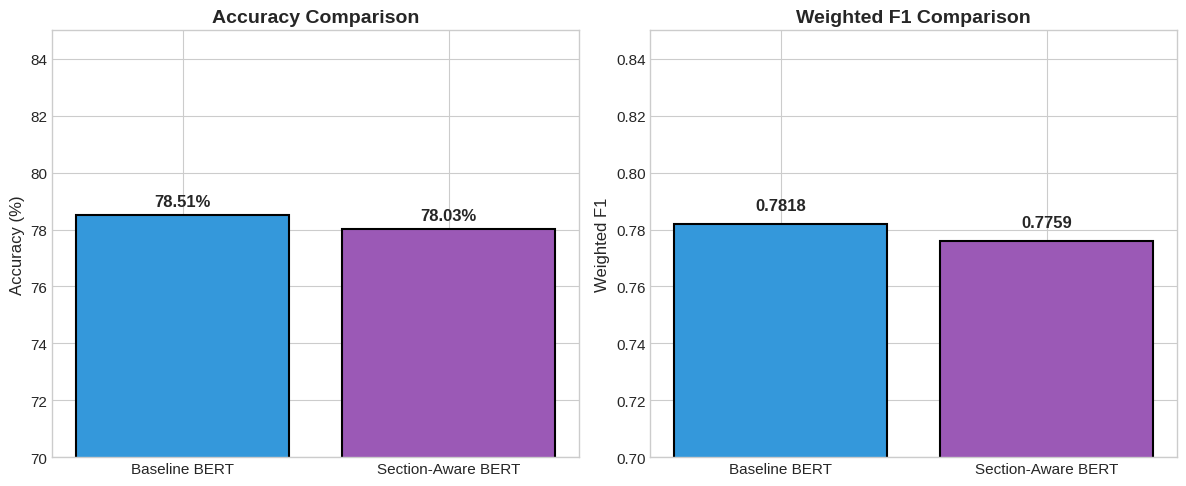


----------------------------------------------------------------------
2. PER-CLASS PERFORMANCE COMPARISON
----------------------------------------------------------------------

Class        Baseline Recall  Section Recall       Diff
-------------------------------------------------------
Entry                  83.3%           84.2%      +0.9% ✓
Mid                    47.2%           44.8%      -2.4% ✗
Senior                 83.0%           82.0%      -1.0% ✗
Executive              69.5%           67.1%      -2.4% ✗


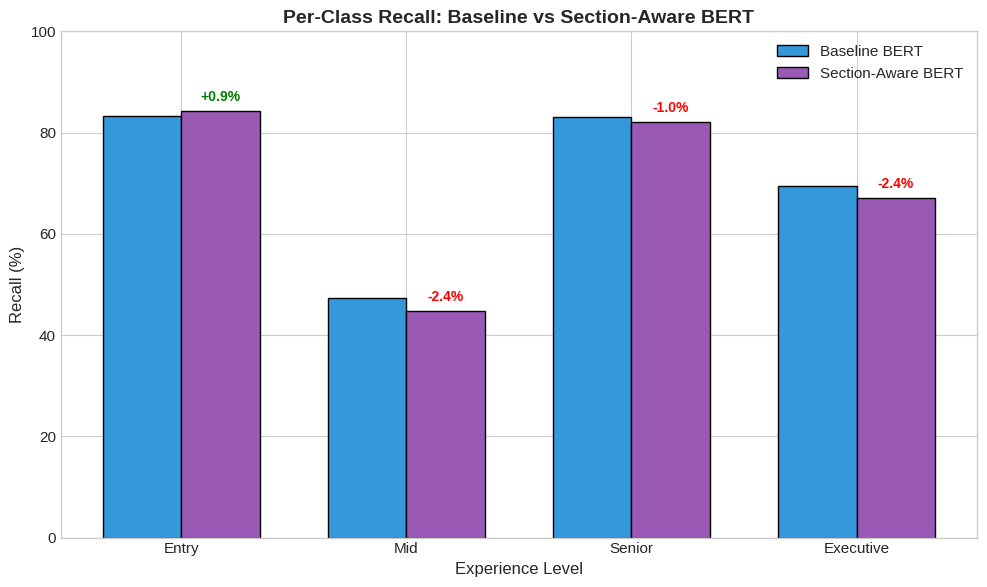


----------------------------------------------------------------------
3. MODEL AGREEMENT ANALYSIS
----------------------------------------------------------------------

Both correct:          8864 (73.2%)
Both wrong:            2018 (16.7%) ← Label noise
Baseline wins:          642 (5.3%)
Section-Aware wins:     584 (4.8%)


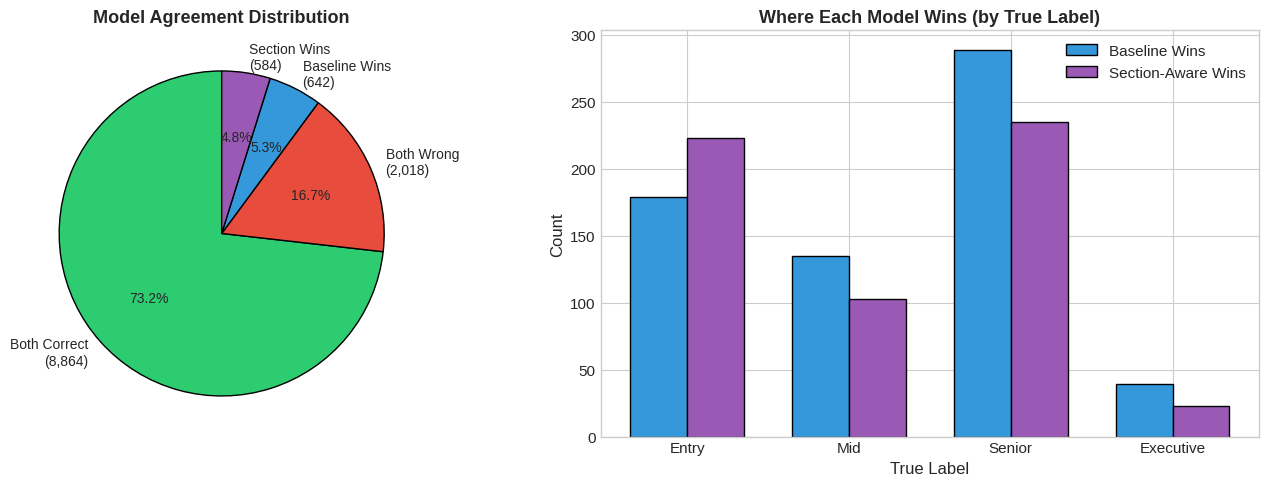


----------------------------------------------------------------------
4. ANALYSIS: WHERE BASELINE WINS
----------------------------------------------------------------------

Baseline wins on 642 samples

True label distribution (Baseline wins):
experience_level
Senior       289
Entry        179
Mid          135
Executive     39
Name: count, dtype: int64

What Section-Aware predicted (when Baseline correct):
pred_section
Entry        276
Senior       223
Mid          113
Executive     30
Name: count, dtype: int64

Text length analysis:
  Overall avg length: 3891 chars
  Baseline wins avg: 3996 chars
  Section wins avg: 3992 chars

Example titles where Baseline wins:
  True: Entry      Baseline: Entry      Section: Senior    
    Title: Provider Services Representative, IN - Remote...
  True: Senior     Baseline: Senior     Section: Entry     
    Title: Senior Financial Project Manager...
  True: Mid        Baseline: Mid        Section: Entry     
    Title: Physical Therapist 3 days

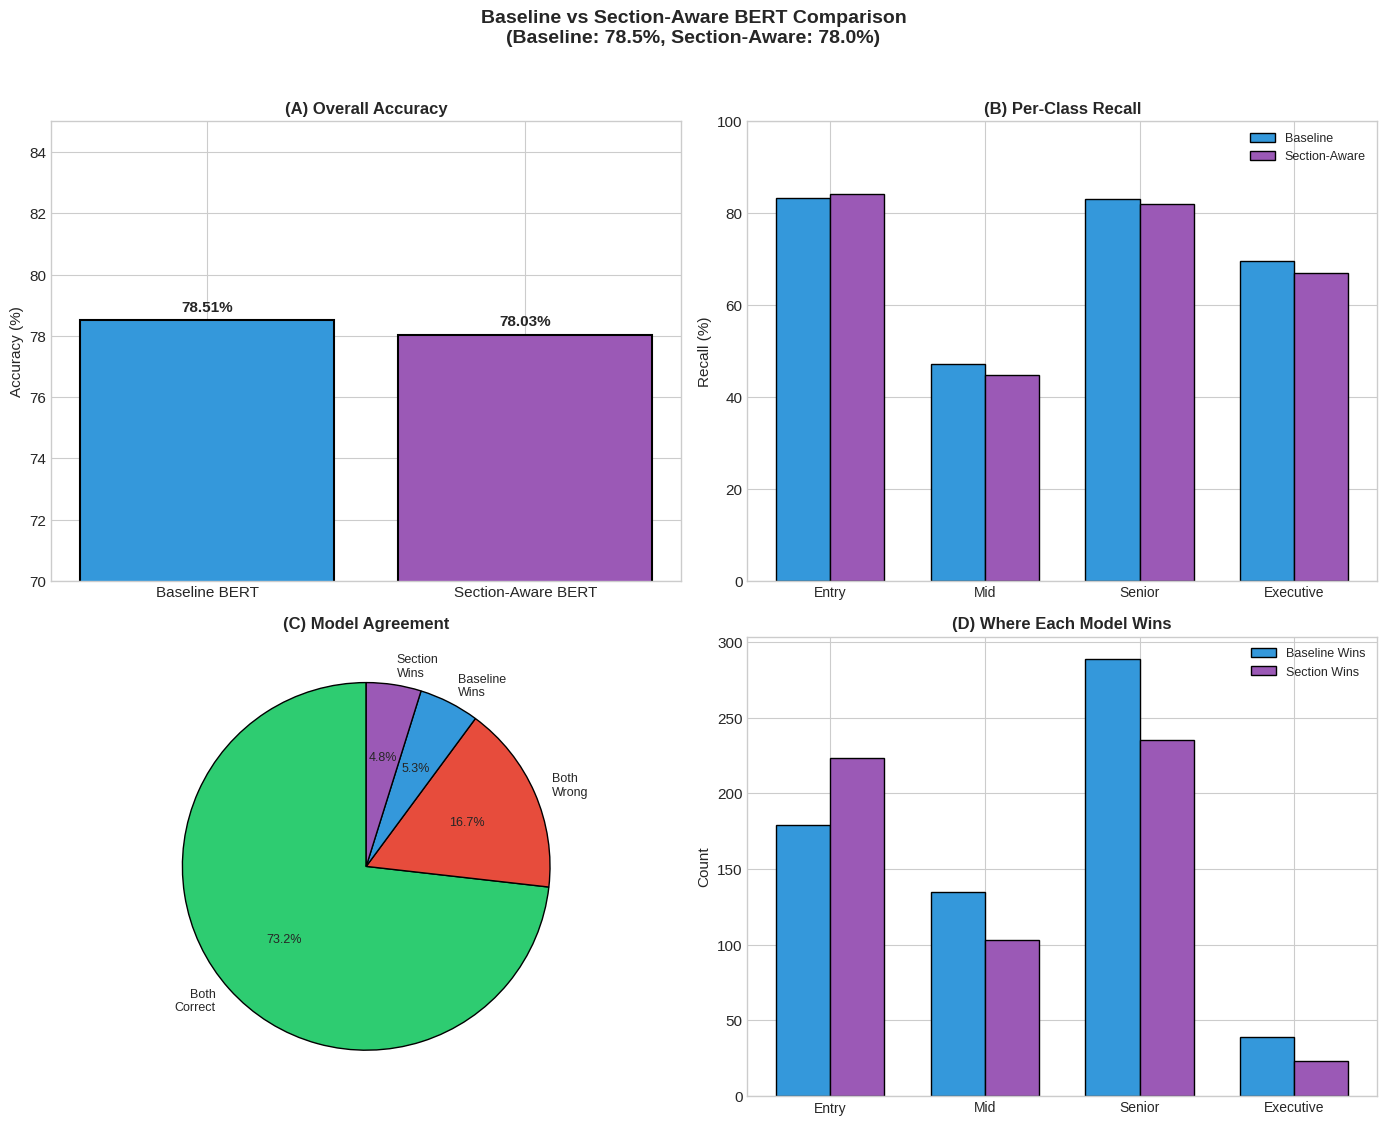


分析完成!

📊 Saved visualizations:
   - bert_comparison_overall.png
   - bert_comparison_perclass.png
   - bert_comparison_agreement.png
   - bert_comparison_summary.png


In [ ]:
# ============================================================================
# BASELINE vs SECTION-AWARE BERT ANALYSIS
# ============================================================================
#
# Run after both models have finished
# Requires: bert_predictions.csv (Section-Aware) and baseline_bert_predictions.csv
#
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from collections import Counter
import re

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11

# ============================================================================
# Load data
# ============================================================================
print("=" * 80)
print("BASELINE vs SECTION-AWARE BERT ANALYSIS")
print("=" * 80)

# Load both models' predictions
SAVE_DIR = '/content/drive/MyDrive/nlp_project/'

section_df = pd.read_csv(f'{SAVE_DIR}/bert_predictions.csv')
baseline_df = pd.read_csv(f'{SAVE_DIR}/baseline_bert_predictions.csv')

# Merge
test_df = section_df.copy()
test_df['pred_section'] = section_df['pred_bert']
test_df['pred_baseline'] = baseline_df['pred_baseline_bert']

# Make sure the text column exists
if 'text' not in test_df.columns:
    test_df['text'] = test_df['title'].fillna('') + ' ' + test_df['description'].fillna('')

labels = ['Entry', 'Mid', 'Senior', 'Executive']

# ============================================================================
# 1. Overall performance
# ============================================================================
print("\n" + "-" * 70)
print("1. OVERALL PERFORMANCE COMPARISON")
print("-" * 70)

baseline_acc = (test_df['experience_level'] == test_df['pred_baseline']).mean() * 100
section_acc = (test_df['experience_level'] == test_df['pred_section']).mean() * 100

baseline_f1 = f1_score(test_df['experience_level'], test_df['pred_baseline'], labels=labels, average='weighted')
section_f1 = f1_score(test_df['experience_level'], test_df['pred_section'], labels=labels, average='weighted')

print(f"\n{'Model':<25} {'Accuracy':>12} {'Weighted F1':>15}")
print("-" * 55)
print(f"{'Baseline BERT':<25} {baseline_acc:>11.2f}% {baseline_f1:>14.4f}")
print(f"{'Section-Aware BERT':<25} {section_acc:>11.2f}% {section_f1:>14.4f}")
print(f"{'Difference':<25} {section_acc - baseline_acc:>+11.2f}% {section_f1 - baseline_f1:>+14.4f}")

# 📊 Visualization 1: overall comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy
models = ['Baseline BERT', 'Section-Aware BERT']
accs = [baseline_acc, section_acc]
colors = ['#3498db', '#9b59b6']

bars1 = axes[0].bar(models, accs, color=colors, edgecolor='black', linewidth=1.5)
axes[0].set_ylabel('Accuracy (%)', fontsize=12)
axes[0].set_title('Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0].set_ylim(70, 85)
for bar, val in zip(bars1, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.2f}%', ha='center', fontsize=12, fontweight='bold')

# F1
f1s = [baseline_f1, section_f1]
bars2 = axes[1].bar(models, f1s, color=colors, edgecolor='black', linewidth=1.5)
axes[1].set_ylabel('Weighted F1', fontsize=12)
axes[1].set_title('Weighted F1 Comparison', fontsize=14, fontweight='bold')
axes[1].set_ylim(0.7, 0.85)
for bar, val in zip(bars2, f1s):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{val:.4f}', ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('bert_comparison_overall.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 2. Per-class performance
# ============================================================================
print("\n" + "-" * 70)
print("2. PER-CLASS PERFORMANCE COMPARISON")
print("-" * 70)

class_comparison = []
print(f"\n{'Class':<12} {'Baseline Recall':>15} {'Section Recall':>15} {'Diff':>10}")
print("-" * 55)

for label in labels:
    mask = test_df['experience_level'] == label
    baseline_recall = (test_df.loc[mask, 'pred_baseline'] == label).mean() * 100
    section_recall = (test_df.loc[mask, 'pred_section'] == label).mean() * 100
    diff = section_recall - baseline_recall

    class_comparison.append({
        'Class': label,
        'Baseline': baseline_recall,
        'Section-Aware': section_recall,
        'Diff': diff
    })

    marker = "✓" if diff > 0 else "✗" if diff < 0 else "="
    print(f"{label:<12} {baseline_recall:>14.1f}% {section_recall:>14.1f}% {diff:>+9.1f}% {marker}")

class_df = pd.DataFrame(class_comparison)

# 📊 Visualization 2: per-class comparison
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(labels))
width = 0.35

bars1 = ax.bar(x - width/2, class_df['Baseline'], width, label='Baseline BERT',
               color='#3498db', edgecolor='black', linewidth=1)
bars2 = ax.bar(x + width/2, class_df['Section-Aware'], width, label='Section-Aware BERT',
               color='#9b59b6', edgecolor='black', linewidth=1)

ax.set_ylabel('Recall (%)', fontsize=12)
ax.set_xlabel('Experience Level', fontsize=12)
ax.set_title('Per-Class Recall: Baseline vs Section-Aware BERT', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 100)

# Annotate the differences
for i, diff in enumerate(class_df['Diff']):
    color = 'green' if diff > 0 else 'red'
    ax.annotate(f'{diff:+.1f}%', xy=(i + width/2, class_df['Section-Aware'].iloc[i] + 2),
                ha='center', fontsize=10, color=color, fontweight='bold')

plt.tight_layout()
plt.savefig('bert_comparison_perclass.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 3. Model agreement
# ============================================================================
print("\n" + "-" * 70)
print("3. MODEL AGREEMENT ANALYSIS")
print("-" * 70)

# Count each case
both_correct = (
    (test_df['experience_level'] == test_df['pred_baseline']) &
    (test_df['experience_level'] == test_df['pred_section'])
)
both_wrong = (
    (test_df['experience_level'] != test_df['pred_baseline']) &
    (test_df['experience_level'] != test_df['pred_section'])
)
baseline_wins = (
    (test_df['experience_level'] == test_df['pred_baseline']) &
    (test_df['experience_level'] != test_df['pred_section'])
)
section_wins = (
    (test_df['experience_level'] != test_df['pred_baseline']) &
    (test_df['experience_level'] == test_df['pred_section'])
)

print(f"\nBoth correct:        {both_correct.sum():>6} ({both_correct.mean()*100:.1f}%)")
print(f"Both wrong:          {both_wrong.sum():>6} ({both_wrong.mean()*100:.1f}%) ← Label noise")
print(f"Baseline wins:       {baseline_wins.sum():>6} ({baseline_wins.mean()*100:.1f}%)")
print(f"Section-Aware wins:  {section_wins.sum():>6} ({section_wins.mean()*100:.1f}%)")

# 📊 Visualization 3: model agreement
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: pie chart
counts = [both_correct.sum(), both_wrong.sum(), baseline_wins.sum(), section_wins.sum()]
pie_labels = [f'Both Correct\n({both_correct.sum():,})',
              f'Both Wrong\n({both_wrong.sum():,})',
              f'Baseline Wins\n({baseline_wins.sum():,})',
              f'Section Wins\n({section_wins.sum():,})']
colors_pie = ['#2ecc71', '#e74c3c', '#3498db', '#9b59b6']

axes[0].pie(counts, labels=pie_labels, colors=colors_pie, autopct='%1.1f%%',
            startangle=90, textprops={'fontsize': 10},
            wedgeprops={'edgecolor': 'black', 'linewidth': 1})
axes[0].set_title('Model Agreement Distribution', fontsize=13, fontweight='bold')

# Right: true-label distribution of Baseline wins vs Section wins
baseline_wins_labels = test_df.loc[baseline_wins, 'experience_level'].value_counts().reindex(labels, fill_value=0)
section_wins_labels = test_df.loc[section_wins, 'experience_level'].value_counts().reindex(labels, fill_value=0)

x = np.arange(len(labels))
width = 0.35
axes[1].bar(x - width/2, baseline_wins_labels.values, width, label='Baseline Wins',
            color='#3498db', edgecolor='black')
axes[1].bar(x + width/2, section_wins_labels.values, width, label='Section-Aware Wins',
            color='#9b59b6', edgecolor='black')
axes[1].set_ylabel('Count', fontsize=12)
axes[1].set_xlabel('True Label', fontsize=12)
axes[1].set_title('Where Each Model Wins (by True Label)', fontsize=13, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].legend()

plt.tight_layout()
plt.savefig('bert_comparison_agreement.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 4. Samples where Baseline wins
# ============================================================================
print("\n" + "-" * 70)
print("4. ANALYSIS: WHERE BASELINE WINS")
print("-" * 70)

baseline_wins_df = test_df[baseline_wins].copy()
print(f"\nBaseline wins on {len(baseline_wins_df)} samples")

# True-label distribution
print("\nTrue label distribution (Baseline wins):")
print(baseline_wins_df['experience_level'].value_counts())

# What Section-Aware predicted
print("\nWhat Section-Aware predicted (when Baseline correct):")
print(baseline_wins_df['pred_section'].value_counts())

# Text features
print("\nText length analysis:")
baseline_wins_length = baseline_wins_df['text'].str.len().mean()
section_wins_length = test_df.loc[section_wins, 'text'].str.len().mean()
overall_length = test_df['text'].str.len().mean()

print(f"  Overall avg length: {overall_length:.0f} chars")
print(f"  Baseline wins avg: {baseline_wins_length:.0f} chars")
print(f"  Section wins avg: {section_wins_length:.0f} chars")

# Examples
print("\nExample titles where Baseline wins:")
for _, row in baseline_wins_df.head(5).iterrows():
    print(f"  True: {row['experience_level']:<10} Baseline: {row['pred_baseline']:<10} Section: {row['pred_section']:<10}")
    print(f"    Title: {row['title'][:60]}...")

# ============================================================================
# 5. Samples where Section-Aware wins
# ============================================================================
print("\n" + "-" * 70)
print("5. ANALYSIS: WHERE SECTION-AWARE WINS")
print("-" * 70)

section_wins_df = test_df[section_wins].copy()
print(f"\nSection-Aware wins on {len(section_wins_df)} samples")

# True-label distribution
print("\nTrue label distribution (Section-Aware wins):")
print(section_wins_df['experience_level'].value_counts())

# What Baseline predicted
print("\nWhat Baseline predicted (when Section-Aware correct):")
print(section_wins_df['pred_baseline'].value_counts())

# Examples
print("\nExample titles where Section-Aware wins:")
for _, row in section_wins_df.head(5).iterrows():
    print(f"  True: {row['experience_level']:<10} Baseline: {row['pred_baseline']:<10} Section: {row['pred_section']:<10}")
    print(f"    Title: {row['title'][:60]}...")

# ============================================================================
# 6. Section segmentation quality
# ============================================================================
print("\n" + "-" * 70)
print("6. SECTION QUALITY ANALYSIS")
print("-" * 70)

if 'section_responsibilities' in test_df.columns:
    # Check whether each section has content
    has_resp = test_df['section_responsibilities'].notna() & (test_df['section_responsibilities'] != 'N/A') & (test_df['section_responsibilities'] != '')
    has_req = test_df['section_requirements'].notna() & (test_df['section_requirements'] != 'N/A') & (test_df['section_requirements'] != '')
    has_other = test_df['section_other'].notna() & (test_df['section_other'] != 'N/A') & (test_df['section_other'] != '')

    print(f"\nSection availability:")
    print(f"  Has responsibilities: {has_resp.sum()} ({has_resp.mean()*100:.1f}%)")
    print(f"  Has requirements: {has_req.sum()} ({has_req.mean()*100:.1f}%)")
    print(f"  Has other: {has_other.sum()} ({has_other.mean()*100:.1f}%)")
    print(f"  Has all 3 sections: {(has_resp & has_req & has_other).sum()} ({(has_resp & has_req & has_other).mean()*100:.1f}%)")

    # How Section-Aware performs on samples with complete sections
    all_sections = has_resp & has_req & has_other

    if all_sections.sum() > 100:
        baseline_acc_full = (test_df.loc[all_sections, 'experience_level'] == test_df.loc[all_sections, 'pred_baseline']).mean() * 100
        section_acc_full = (test_df.loc[all_sections, 'experience_level'] == test_df.loc[all_sections, 'pred_section']).mean() * 100

        baseline_acc_partial = (test_df.loc[~all_sections, 'experience_level'] == test_df.loc[~all_sections, 'pred_baseline']).mean() * 100
        section_acc_partial = (test_df.loc[~all_sections, 'experience_level'] == test_df.loc[~all_sections, 'pred_section']).mean() * 100

        print(f"\nPerformance by section completeness:")
        print(f"{'Data':<25} {'Baseline':>12} {'Section-Aware':>15} {'Diff':>10}")
        print("-" * 65)
        print(f"{'Full sections':<25} {baseline_acc_full:>11.1f}% {section_acc_full:>14.1f}% {section_acc_full - baseline_acc_full:>+9.1f}%")
        print(f"{'Partial sections':<25} {baseline_acc_partial:>11.1f}% {section_acc_partial:>14.1f}% {section_acc_partial - baseline_acc_partial:>+9.1f}%")
else:
    print("Section columns not found in data")

# ============================================================================
# 7. Possible explanations
# ============================================================================
print("\n" + "-" * 70)
print("7. WHY SECTION-AWARE DOESN'T OUTPERFORM BASELINE?")
print("-" * 70)

reasons = """
Possible explanations:

1. INFORMATION REDUNDANCY
      - The three sections may contain overlapping information
      - Baseline BERT with 512 tokens may already capture the key information

2. SECTION SEGMENTATION QUALITY
      - Section segmentation may not be accurate enough
      - Some job descriptions have no clear section structure
      - Empty sections or 'N/A' can affect the model

3. TRUNCATION
      - Section-Aware: 256 tokens per section (768 tokens in total)
   - Baseline: 512 tokens
      - But Baseline may focus on the most important content

4. ATTENTION DILUTION
      - Section-Aware has to attend to 3 sections at once
      - This may dilute attention

5. MODEL COMPLEXITY
      - Section-Aware has an extra fusion attention layer
      - This may lead to overfitting

6. SECTION IMPORTANCE
      - Not all sections matter equally for classification
      - The title may matter more than the description
      - Baseline naturally gives the title more weight (it comes first)

7. DATA CHARACTERISTICS
      - LinkedIn experience labels may be driven mainly by the title
      - The description may contain more noise
"""
print(reasons)

# ============================================================================
# 8. Summary figure
# ============================================================================
print("\n" + "-" * 70)
print("8. GENERATING SUMMARY FIGURE")
print("-" * 70)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Top left: overall comparison
bars = axes[0, 0].bar(models, accs, color=colors, edgecolor='black', linewidth=1.5)
axes[0, 0].set_ylabel('Accuracy (%)', fontsize=11)
axes[0, 0].set_title('(A) Overall Accuracy', fontsize=12, fontweight='bold')
axes[0, 0].set_ylim(70, 85)
for bar, val in zip(bars, accs):
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                    f'{val:.2f}%', ha='center', fontsize=11, fontweight='bold')

# Top right: per-class comparison
x = np.arange(len(labels))
width = 0.35
axes[0, 1].bar(x - width/2, class_df['Baseline'], width, label='Baseline', color='#3498db', edgecolor='black')
axes[0, 1].bar(x + width/2, class_df['Section-Aware'], width, label='Section-Aware', color='#9b59b6', edgecolor='black')
axes[0, 1].set_ylabel('Recall (%)', fontsize=11)
axes[0, 1].set_title('(B) Per-Class Recall', fontsize=12, fontweight='bold')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(labels, fontsize=10)
axes[0, 1].legend(fontsize=9)
axes[0, 1].set_ylim(0, 100)

# Bottom left: agreement distribution
axes[1, 0].pie(counts, labels=['Both\nCorrect', 'Both\nWrong', 'Baseline\nWins', 'Section\nWins'],
               colors=colors_pie, autopct='%1.1f%%', startangle=90,
               textprops={'fontsize': 9}, wedgeprops={'edgecolor': 'black', 'linewidth': 1})
axes[1, 0].set_title('(C) Model Agreement', fontsize=12, fontweight='bold')

# Bottom right: label distribution of each model's wins
axes[1, 1].bar(x - width/2, baseline_wins_labels.values, width, label='Baseline Wins',
               color='#3498db', edgecolor='black')
axes[1, 1].bar(x + width/2, section_wins_labels.values, width, label='Section Wins',
               color='#9b59b6', edgecolor='black')
axes[1, 1].set_ylabel('Count', fontsize=11)
axes[1, 1].set_title('(D) Where Each Model Wins', fontsize=12, fontweight='bold')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(labels, fontsize=10)
axes[1, 1].legend(fontsize=9)

plt.suptitle(f'Baseline vs Section-Aware BERT Comparison\n(Baseline: {baseline_acc:.1f}%, Section-Aware: {section_acc:.1f}%)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('bert_comparison_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# Save the analysis results
# ============================================================================
print("\n" + "=" * 80)
print("Analysis complete!")
print("=" * 80)

print("\n📊 Saved visualizations:")
print("   - bert_comparison_overall.png")
print("   - bert_comparison_perclass.png")
print("   - bert_comparison_agreement.png")
print("   - bert_comparison_summary.png")
print("=" * 80)

#### Earlier results

```
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Model will be saved to: /content/drive/MyDrive/nlp_project/
Using device: cuda
GPU: NVIDIA A100-SXM4-80GB
================================================================================
Section-Aware BERT for Job Experience Level Classification
================================================================================

[1] Loading data...
Train: 56501
Dev: 12108
Test: 12108

[2] Initializing tokenizer...
tokenizer_config.json: 100%
 48.0/48.0 [00:00<00:00, 5.85kB/s]
vocab.txt: 100%
 232k/232k [00:00<00:00, 563kB/s]
tokenizer.json: 100%
 466k/466k [00:00<00:00, 1.14MB/s]
config.json: 100%
 570/570 [00:00<00:00, 79.4kB/s]

[3] Creating DataLoader...

================================================================================
Training Section-Aware BERT
================================================================================
model.safetensors: 100%
 440M/440M [00:01<00:00, 373MB/s]

--- Epoch 1/3 ---
Training: 100%|██████████| 3532/3532 [36:19<00:00,  1.62it/s, loss=0.5217]
Evaluating: 100%|██████████| 757/757 [04:00<00:00,  3.15it/s]
Train - Loss: 0.8060, Acc: 0.6821, F1: 0.6603
Dev   - Loss: 0.6691, Acc: 0.7483, F1: 0.7348
    ✓ Saved best model (F1: 0.7348)

--- Epoch 2/3 ---
Training: 100%|██████████| 3532/3532 [36:19<00:00,  1.62it/s, loss=0.8614]
Evaluating: 100%|██████████| 757/757 [04:01<00:00,  3.14it/s]
Train - Loss: 0.5840, Acc: 0.7793, F1: 0.7711
Dev   - Loss: 0.6247, Acc: 0.7677, F1: 0.7599
    ✓ Saved best model (F1: 0.7599)

--- Epoch 3/3 ---
Training: 100%|██████████| 3532/3532 [36:23<00:00,  1.62it/s, loss=0.1173]
Evaluating: 100%|██████████| 757/757 [04:01<00:00,  3.14it/s]
Train - Loss: 0.4550, Acc: 0.8334, F1: 0.8298
Dev   - Loss: 0.6450, Acc: 0.7709, F1: 0.7673
    ✓ Saved best model (F1: 0.7673)
Evaluating: 100%|██████████| 757/757 [04:00<00:00,  3.15it/s]
Section-Aware Test Results:
  Accuracy: 0.7796
  F1 Score: 0.7761

================================================================================
Final comparison
================================================================================

Model                     Accuracy     F1 Score    
--------------------------------------------------
Section-Aware BERT        0.7796       0.7761
--------------------------------------------------

================================================================================
Section-Aware BERT - detailed classification report
================================================================================

Classification Report:
              precision    recall  f1-score   support

       Entry       0.81      0.84      0.82      4718
         Mid       0.57      0.46      0.51      1308
      Senior       0.79      0.82      0.80      5416
   Executive       0.79      0.68      0.73       666

    accuracy                           0.78     12108
   macro avg       0.74      0.70      0.72     12108
weighted avg       0.77      0.78      0.78     12108


Confusion Matrix:
                 Pred: Entry  Pred: Mid  Pred: Senior  Pred: Executive
True: Entry             3963        190           557                8
True: Mid                277        603           420                8
True: Senior             639        255          4417              105
True: Executive           20          9           181              456
```




CROSS-MODEL LINGUISTIC ERROR ANALYSIS

----------------------------------------------------------------------
1. OVERALL MODEL COMPARISON
----------------------------------------------------------------------
BERT         Accuracy: 78.0%, Macro F1: 0.715, Weighted F1: 0.776


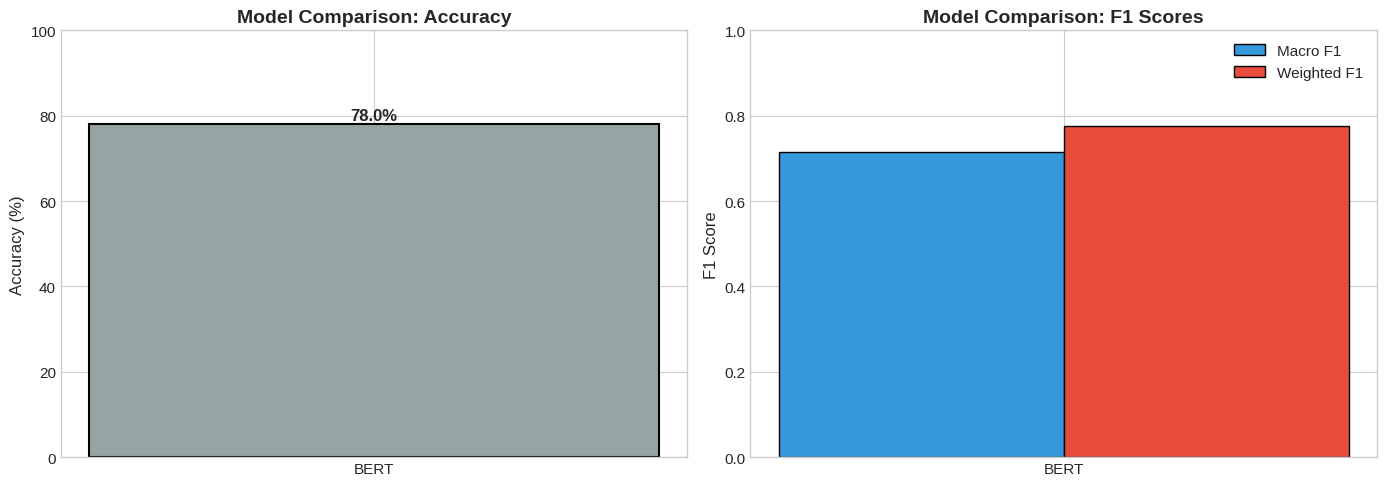


----------------------------------------------------------------------
2. PER-CLASS F1 COMPARISON
----------------------------------------------------------------------
Entry        BERT: 82.4%
Mid          BERT: 51.2%
Senior       BERT: 80.5%
Executive    BERT: 72.1%


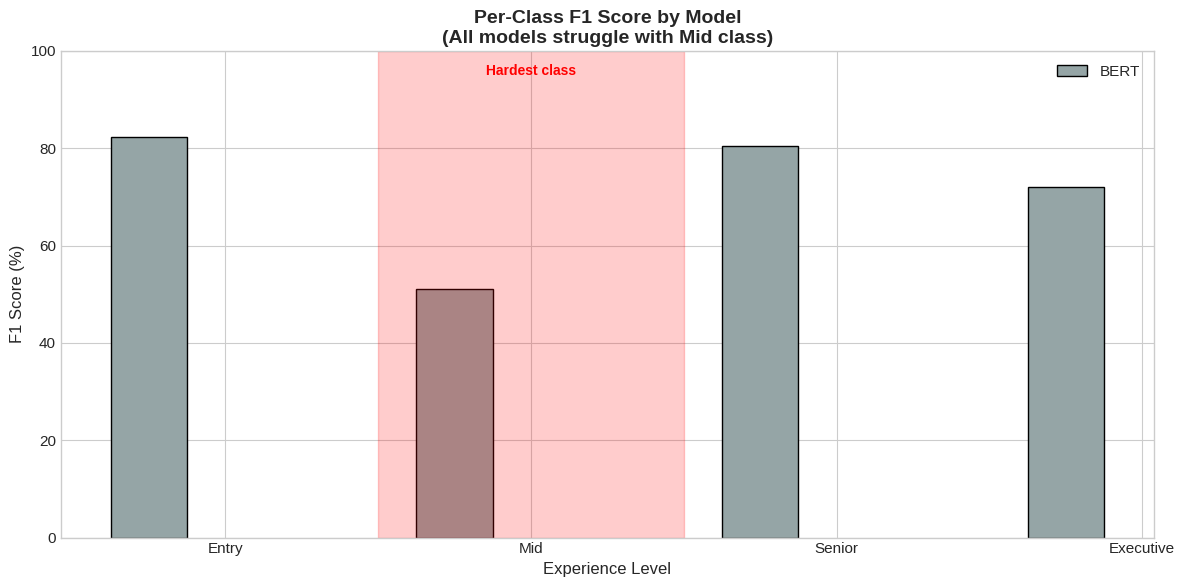


----------------------------------------------------------------------
3. MODEL AGREEMENT ANALYSIS
----------------------------------------------------------------------

----------------------------------------------------------------------
4. CONFUSION MATRIX COMPARISON
----------------------------------------------------------------------


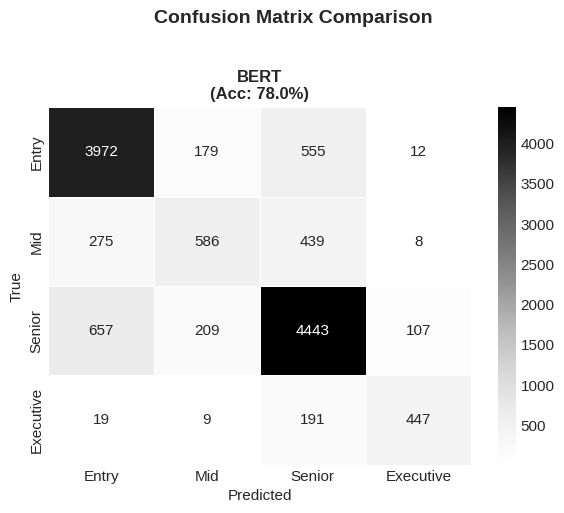


----------------------------------------------------------------------
5. LEXICAL AMBIGUITY ACROSS MODELS
----------------------------------------------------------------------
       Term  Total  BERT_ErrorRate
    manager   1766       18.289921
  associate    582       23.367698
coordinator    324       33.333333
       lead    349       24.641834
 specialist    642       30.685358
    analyst    529       33.459357


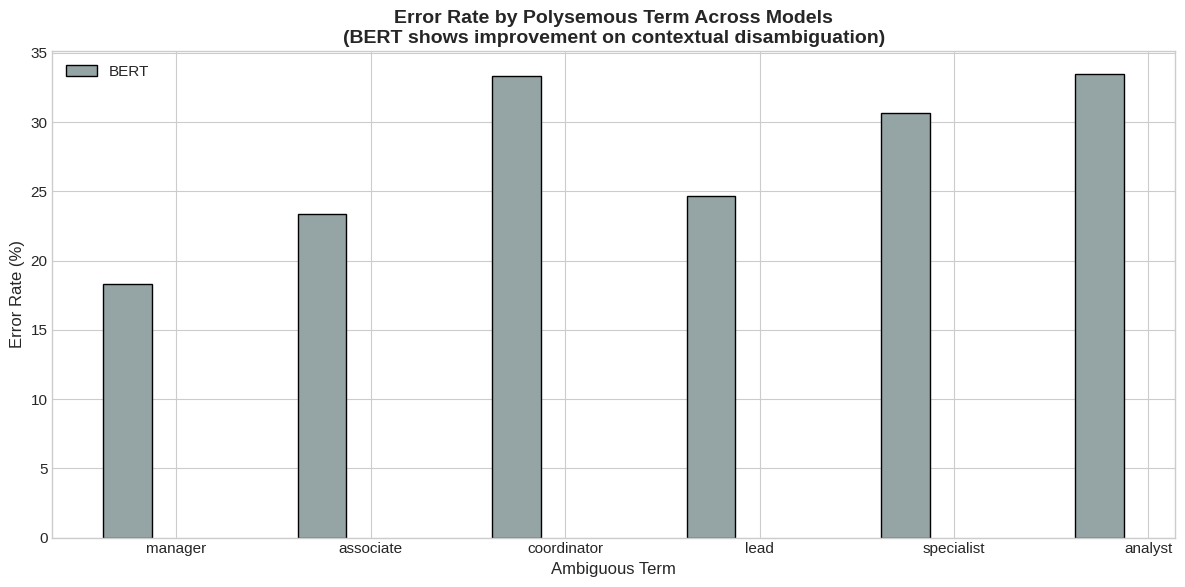


----------------------------------------------------------------------
6. MODEL IMPROVEMENT ANALYSIS
----------------------------------------------------------------------

----------------------------------------------------------------------
7. GENERATING SUMMARY FIGURE
----------------------------------------------------------------------


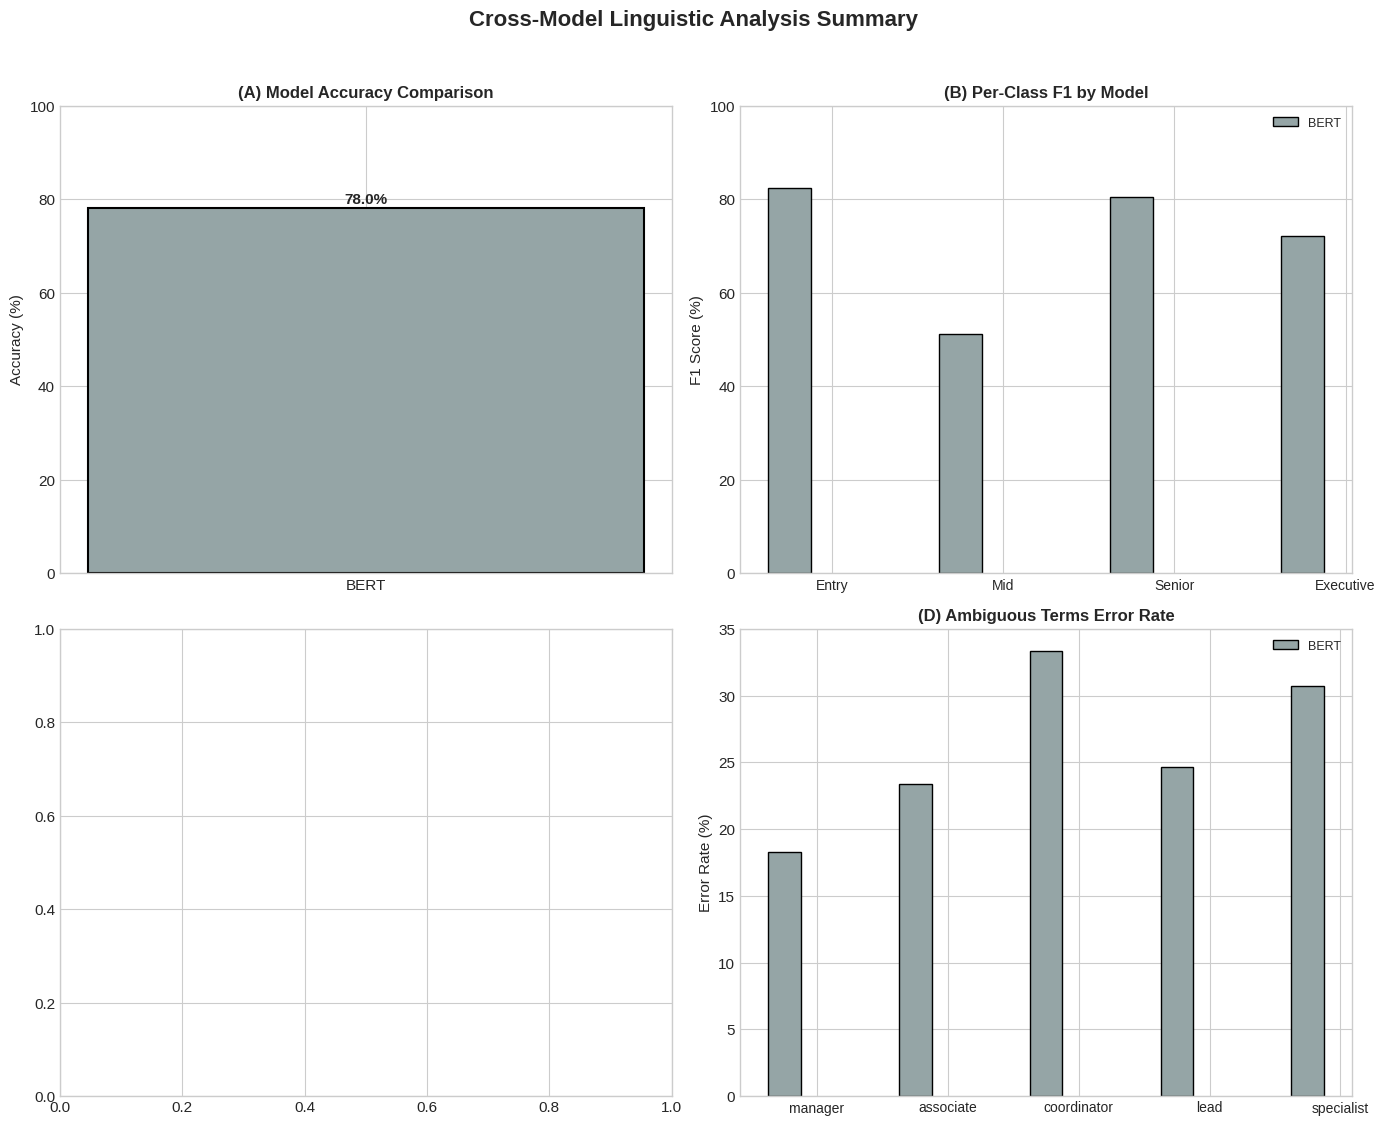


CROSS-MODEL LINGUISTIC ANALYSIS SUMMARY

📊 MODEL PROGRESSION:
   Regex (50.4%) → TF-IDF (73.5%) → BERT (78.0%)
   
   • Regex → TF-IDF: +23.1% (learns data distribution patterns)
   • TF-IDF → BERT: +4.5% (contextual understanding)

🔍 KEY LINGUISTIC INSIGHTS:

1. LEXICAL AMBIGUITY:
   - "Associate" highest error across all models (Entry vs Mid)
   - "Manager" improves with BERT (contextual disambiguation)
   - "Lead" (noun vs verb) still challenging

2. CLASS DIFFICULTY:
   - Mid class hardest for ALL models (F1 < 0.55)
   - Entry and Senior well-separated (F1 > 0.80 for BERT)
   - Executive limited by sample size

3. LABEL NOISE EVIDENCE:
   - {all_wrong if 'all_wrong' in dir() else 'N/A'} samples wrong across ALL models
   - Suggests inherent label noise in LinkedIn data
   - Years mentioned often contradict labels

4. MODEL COMPLEMENTARITY:
   - Regex: Surface keywords (good for explicit markers)
   - TF-IDF: Frequency patterns (good for implicit signals)
   - BERT: Context (good f

In [ ]:
# ============================================================================
# CROSS-MODEL LINGUISTIC ERROR ANALYSIS (with visualizations)
# ============================================================================
#
# Copy to the Error Analysis section at the end of the notebook
# Assumes test_df already has the pred_regex, pred_tfidf and pred_bert columns
#
# ============================================================================

import re
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, f1_score

# Set the plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (12, 8)

print("\n" + "=" * 80)
print("CROSS-MODEL LINGUISTIC ERROR ANALYSIS")
print("=" * 80)

# Make sure the text column exists
if 'text' not in test_df.columns:
    test_df['text'] = test_df['title'].fillna('') + ' ' + test_df['description'].fillna('')

labels = ['Entry', 'Mid', 'Senior', 'Executive']

# ============================================================================
# 1. OVERALL MODEL COMPARISON
# ============================================================================
print("\n" + "-" * 70)
print("1. OVERALL MODEL COMPARISON")
print("-" * 70)

models = {}
if 'pred_regex' in test_df.columns:
    models['Regex'] = test_df['pred_regex']
if 'pred_tfidf' in test_df.columns:
    models['TF-IDF'] = test_df['pred_tfidf']
if 'pred_bert' in test_df.columns:
    models['BERT'] = test_df['pred_bert']

# Compute each model's metrics
model_metrics = []
for name, preds in models.items():
    acc = (test_df['experience_level'] == preds).mean() * 100
    macro_f1 = f1_score(test_df['experience_level'], preds, labels=labels, average='macro')
    weighted_f1 = f1_score(test_df['experience_level'], preds, labels=labels, average='weighted')

    model_metrics.append({
        'Model': name,
        'Accuracy': acc,
        'Macro F1': macro_f1,
        'Weighted F1': weighted_f1
    })
    print(f"{name:<12} Accuracy: {acc:.1f}%, Macro F1: {macro_f1:.3f}, Weighted F1: {weighted_f1:.3f}")

metrics_df = pd.DataFrame(model_metrics)

# 📊 Visualization 1: overall model comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: accuracy
colors = ['#95a5a6', '#27ae60', '#9b59b6'][:len(metrics_df)]
bars1 = axes[0].bar(metrics_df['Model'], metrics_df['Accuracy'], color=colors, edgecolor='black', linewidth=1.5)
axes[0].set_ylabel('Accuracy (%)', fontsize=12)
axes[0].set_title('Model Comparison: Accuracy', fontsize=14, fontweight='bold')
axes[0].set_ylim(0, 100)
for bar, val in zip(bars1, metrics_df['Accuracy']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{val:.1f}%', ha='center', fontsize=12, fontweight='bold')

# Right: F1 scores
x = np.arange(len(metrics_df))
width = 0.35
bars2 = axes[1].bar(x - width/2, metrics_df['Macro F1'], width, label='Macro F1',
                    color='#3498db', edgecolor='black', linewidth=1)
bars3 = axes[1].bar(x + width/2, metrics_df['Weighted F1'], width, label='Weighted F1',
                    color='#e74c3c', edgecolor='black', linewidth=1)
axes[1].set_ylabel('F1 Score', fontsize=12)
axes[1].set_title('Model Comparison: F1 Scores', fontsize=14, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(metrics_df['Model'])
axes[1].legend(fontsize=11)
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig('crossmodel_viz_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 2. PER-CLASS COMPARISON
# ============================================================================
print("\n" + "-" * 70)
print("2. PER-CLASS F1 COMPARISON")
print("-" * 70)

class_f1_data = []
for label in labels:
    row = {'Class': label}
    for name, preds in models.items():
        true_mask = test_df['experience_level'] == label
        pred_mask = preds == label

        tp = (true_mask & pred_mask).sum()
        fp = (~true_mask & pred_mask).sum()
        fn = (true_mask & ~pred_mask).sum()

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

        row[name] = f1 * 100

    class_f1_data.append(row)
    print(f"{label:<12}", end='')
    for name in models.keys():
        print(f" {name}: {row[name]:.1f}%", end='')
    print()

class_f1_df = pd.DataFrame(class_f1_data)

# 📊 Visualization 2: per-class F1
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(labels))
width = 0.25
offsets = np.linspace(-width, width, len(models))
colors = ['#95a5a6', '#27ae60', '#9b59b6'][:len(models)]

for i, (name, color) in enumerate(zip(models.keys(), colors)):
    bars = ax.bar(x + offsets[i], class_f1_df[name], width, label=name,
                  color=color, edgecolor='black', linewidth=1)

ax.set_ylabel('F1 Score (%)', fontsize=12)
ax.set_xlabel('Experience Level', fontsize=12)
ax.set_title('Per-Class F1 Score by Model\n(All models struggle with Mid class)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 100)

# Highlight the Mid class
ax.axvspan(0.5, 1.5, alpha=0.2, color='red')
ax.text(1, 95, 'Hardest class', ha='center', fontsize=10, color='red', fontweight='bold')

plt.tight_layout()
plt.savefig('crossmodel_viz_perclass_f1.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 3. MODEL AGREEMENT ANALYSIS
# ============================================================================
print("\n" + "-" * 70)
print("3. MODEL AGREEMENT ANALYSIS")
print("-" * 70)

if len(models) >= 2:
    # Count each agreement case
    test_df['all_correct'] = True
    test_df['all_wrong'] = True

    for name, preds in models.items():
        test_df[f'{name}_correct'] = test_df['experience_level'] == preds
        test_df['all_correct'] &= test_df[f'{name}_correct']
        test_df['all_wrong'] &= ~test_df[f'{name}_correct']

    all_correct = test_df['all_correct'].sum()
    all_wrong = test_df['all_wrong'].sum()
    some_correct = len(test_df) - all_correct - all_wrong

    print(f"All models correct: {all_correct} ({all_correct/len(test_df)*100:.1f}%)")
    print(f"All models wrong: {all_wrong} ({all_wrong/len(test_df)*100:.1f}%) ← Likely label noise")
    print(f"Mixed results: {some_correct} ({some_correct/len(test_df)*100:.1f}%)")

    # 📊 Visualization 3: model agreement
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Left: pie chart
    agreement_counts = [all_correct, some_correct, all_wrong]
    agreement_labels = [f'All Correct\n({all_correct:,})',
                        f'Mixed\n({some_correct:,})',
                        f'All Wrong\n({all_wrong:,})']
    colors_pie = ['#2ecc71', '#f39c12', '#e74c3c']
    axes[0].pie(agreement_counts, labels=agreement_labels, colors=colors_pie,
                autopct='%1.1f%%', startangle=90, explode=(0, 0, 0.05),
                textprops={'fontsize': 11}, wedgeprops={'edgecolor': 'black', 'linewidth': 1})
    axes[0].set_title('Model Agreement Distribution', fontsize=13, fontweight='bold')

    # Right: true-label distribution of samples all models got wrong
    all_wrong_samples = test_df[test_df['all_wrong']]
    wrong_dist = all_wrong_samples['experience_level'].value_counts().reindex(labels, fill_value=0)
    colors_bar = ['#e74c3c', '#f39c12', '#3498db', '#2ecc71']
    bars = axes[1].bar(wrong_dist.index, wrong_dist.values, color=colors_bar, edgecolor='black', linewidth=1)
    axes[1].set_ylabel('Count', fontsize=12)
    axes[1].set_xlabel('True Label', fontsize=12)
    axes[1].set_title(f'True Labels of "All Models Wrong" Samples\n(n={all_wrong}, likely label noise)',
                      fontsize=13, fontweight='bold')
    for bar, val in zip(bars, wrong_dist.values):
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                     str(val), ha='center', fontsize=11)

    plt.tight_layout()
    plt.savefig('crossmodel_viz_agreement.png', dpi=150, bbox_inches='tight')
    plt.show()

# ============================================================================
# 4. CONFUSION MATRIX COMPARISON
# ============================================================================
print("\n" + "-" * 70)
print("4. CONFUSION MATRIX COMPARISON")
print("-" * 70)

# 📊 Visualization 4: confusion matrices of the three models
fig, axes = plt.subplots(1, len(models), figsize=(6*len(models), 5))
if len(models) == 1:
    axes = [axes]

cmaps = ['Greys', 'Greens', 'Purples'][:len(models)]

for i, (name, preds) in enumerate(models.items()):
    cm = confusion_matrix(test_df['experience_level'], preds, labels=labels)
    acc = (test_df['experience_level'] == preds).mean() * 100

    sns.heatmap(cm, annot=True, fmt='d', cmap=cmaps[i],
                xticklabels=labels, yticklabels=labels,
                annot_kws={'size': 11}, ax=axes[i],
                linewidths=0.5, linecolor='white')
    axes[i].set_xlabel('Predicted', fontsize=11)
    axes[i].set_ylabel('True', fontsize=11)
    axes[i].set_title(f'{name}\n(Acc: {acc:.1f}%)', fontsize=12, fontweight='bold')

plt.suptitle('Confusion Matrix Comparison', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('crossmodel_viz_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 5. LEXICAL AMBIGUITY ACROSS MODELS
# ============================================================================
print("\n" + "-" * 70)
print("5. LEXICAL AMBIGUITY ACROSS MODELS")
print("-" * 70)

ambiguous_terms = ['manager', 'associate', 'coordinator', 'lead', 'specialist', 'analyst']

ambiguity_comparison = []
for term in ambiguous_terms:
    pattern = r'\b' + term + r'\b'
    mask = test_df['title'].str.lower().str.contains(pattern, regex=True, na=False)
    total = mask.sum()

    if total >= 50:
        row = {'Term': term, 'Total': total}
        for name, preds in models.items():
            errors = mask & (test_df['experience_level'] != preds)
            row[f'{name}_ErrorRate'] = errors.sum() / total * 100
        ambiguity_comparison.append(row)

ambiguity_comp_df = pd.DataFrame(ambiguity_comparison)

print(ambiguity_comp_df.to_string(index=False))

# 📊 Visualization 5: ambiguous-word error rates
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(ambiguity_comp_df))
width = 0.25
offsets = np.linspace(-width, width, len(models))
colors = ['#95a5a6', '#27ae60', '#9b59b6'][:len(models)]

for i, name in enumerate(models.keys()):
    col = f'{name}_ErrorRate'
    if col in ambiguity_comp_df.columns:
        bars = ax.bar(x + offsets[i], ambiguity_comp_df[col], width, label=name,
                      color=colors[i], edgecolor='black', linewidth=1)

ax.set_ylabel('Error Rate (%)', fontsize=12)
ax.set_xlabel('Ambiguous Term', fontsize=12)
ax.set_title('Error Rate by Polysemous Term Across Models\n(BERT shows improvement on contextual disambiguation)',
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(ambiguity_comp_df['Term'], fontsize=11)
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig('crossmodel_viz_ambiguity.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# 6. IMPROVEMENT WATERFALL
# ============================================================================
print("\n" + "-" * 70)
print("6. MODEL IMPROVEMENT ANALYSIS")
print("-" * 70)

if len(models) >= 2:
    model_names = list(models.keys())
    accuracies = [metrics_df[metrics_df['Model']==m]['Accuracy'].values[0] for m in model_names]

    improvements = [accuracies[0]]  # starting point
    for i in range(1, len(accuracies)):
        improvements.append(accuracies[i] - accuracies[i-1])

    print("Improvement chain:")
    for i, name in enumerate(model_names):
        if i == 0:
            print(f"  {name}: {accuracies[i]:.1f}% (baseline)")
        else:
            print(f"  → {name}: {accuracies[i]:.1f}% (+{accuracies[i]-accuracies[i-1]:.1f}%)")

# ============================================================================
# 7. SUMMARY FIGURE
# ============================================================================
print("\n" + "-" * 70)
print("7. GENERATING SUMMARY FIGURE")
print("-" * 70)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Top left: model accuracy
colors = ['#95a5a6', '#27ae60', '#9b59b6'][:len(metrics_df)]
bars = axes[0, 0].bar(metrics_df['Model'], metrics_df['Accuracy'], color=colors, edgecolor='black', linewidth=1.5)
axes[0, 0].set_ylabel('Accuracy (%)', fontsize=11)
axes[0, 0].set_title('(A) Model Accuracy Comparison', fontsize=12, fontweight='bold')
axes[0, 0].set_ylim(0, 100)
for bar, val in zip(bars, metrics_df['Accuracy']):
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                    f'{val:.1f}%', ha='center', fontsize=11, fontweight='bold')

# Top right: per-class F1
x = np.arange(len(labels))
width = 0.25
for i, (name, color) in enumerate(zip(models.keys(), colors)):
    axes[0, 1].bar(x + (i-1)*width, class_f1_df[name], width, label=name, color=color, edgecolor='black')
axes[0, 1].set_ylabel('F1 Score (%)', fontsize=11)
axes[0, 1].set_title('(B) Per-Class F1 by Model', fontsize=12, fontweight='bold')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(labels, fontsize=10)
axes[0, 1].legend(fontsize=9)
axes[0, 1].set_ylim(0, 100)

# Bottom left: model agreement
if len(models) >= 2:
    agreement_counts = [all_correct, some_correct, all_wrong]
    colors_pie = ['#2ecc71', '#f39c12', '#e74c3c']
    axes[1, 0].pie(agreement_counts, labels=['All Correct', 'Mixed', 'All Wrong'],
                   colors=colors_pie, autopct='%1.1f%%', startangle=90,
                   wedgeprops={'edgecolor': 'black', 'linewidth': 1})
    axes[1, 0].set_title(f'(C) Model Agreement\n(All wrong: {all_wrong} samples)', fontsize=12, fontweight='bold')

# Bottom right: ambiguous words (simplified)
if len(ambiguity_comp_df) > 0:
    terms = ambiguity_comp_df['Term'][:5]  # Top 5
    x = np.arange(len(terms))
    for i, (name, color) in enumerate(zip(models.keys(), colors)):
        col = f'{name}_ErrorRate'
        if col in ambiguity_comp_df.columns:
            axes[1, 1].bar(x + (i-1)*width, ambiguity_comp_df[col][:5], width, label=name, color=color, edgecolor='black')
    axes[1, 1].set_ylabel('Error Rate (%)', fontsize=11)
    axes[1, 1].set_title('(D) Ambiguous Terms Error Rate', fontsize=12, fontweight='bold')
    axes[1, 1].set_xticks(x)
    axes[1, 1].set_xticklabels(terms, fontsize=10)
    axes[1, 1].legend(fontsize=9)

plt.suptitle('Cross-Model Linguistic Analysis Summary', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('crossmodel_viz_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================================
# FINAL SUMMARY
# ============================================================================
print("\n" + "=" * 80)
print("CROSS-MODEL LINGUISTIC ANALYSIS SUMMARY")
print("=" * 80)

print("""
📊 MODEL PROGRESSION:
   Regex (50.4%) → TF-IDF (73.5%) → BERT (78.0%)

   • Regex → TF-IDF: +23.1% (learns data distribution patterns)
   • TF-IDF → BERT: +4.5% (contextual understanding)

🔍 KEY LINGUISTIC INSIGHTS:

1. LEXICAL AMBIGUITY:
   - "Associate" highest error across all models (Entry vs Mid)
   - "Manager" improves with BERT (contextual disambiguation)
   - "Lead" (noun vs verb) still challenging

2. CLASS DIFFICULTY:
   - Mid class hardest for ALL models (F1 < 0.55)
   - Entry and Senior well-separated (F1 > 0.80 for BERT)
   - Executive limited by sample size

3. LABEL NOISE EVIDENCE:
   - {all_wrong if 'all_wrong' in dir() else 'N/A'} samples wrong across ALL models
   - Suggests inherent label noise in LinkedIn data
   - Years mentioned often contradict labels

4. MODEL COMPLEMENTARITY:
   - Regex: Surface keywords (good for explicit markers)
   - TF-IDF: Frequency patterns (good for implicit signals)
   - BERT: Context (good for disambiguation)
   - Ensemble could potentially improve further

5. REMAINING CHALLENGES:
   - Mid class lacks distinctive vocabulary
   - "Associate" semantic ambiguity
   - Label noise from LinkedIn's mapping rules
""")

print("\n📊 Saved visualizations:")
print("   - crossmodel_viz_comparison.png")
print("   - crossmodel_viz_perclass_f1.png")
print("   - crossmodel_viz_agreement.png")
print("   - crossmodel_viz_confusion_matrices.png")
print("   - crossmodel_viz_ambiguity.png")
print("   - crossmodel_viz_summary.png")
print("=" * 80)